In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from skimage import data

def mostrar(imagens, titulos, cmap=None, tamanho=4):
    n = len(imagens)
    plt.figure(figsize=(tamanho * n, tamanho))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(imagens[i], cmap=cmap)
        plt.title(titulos[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

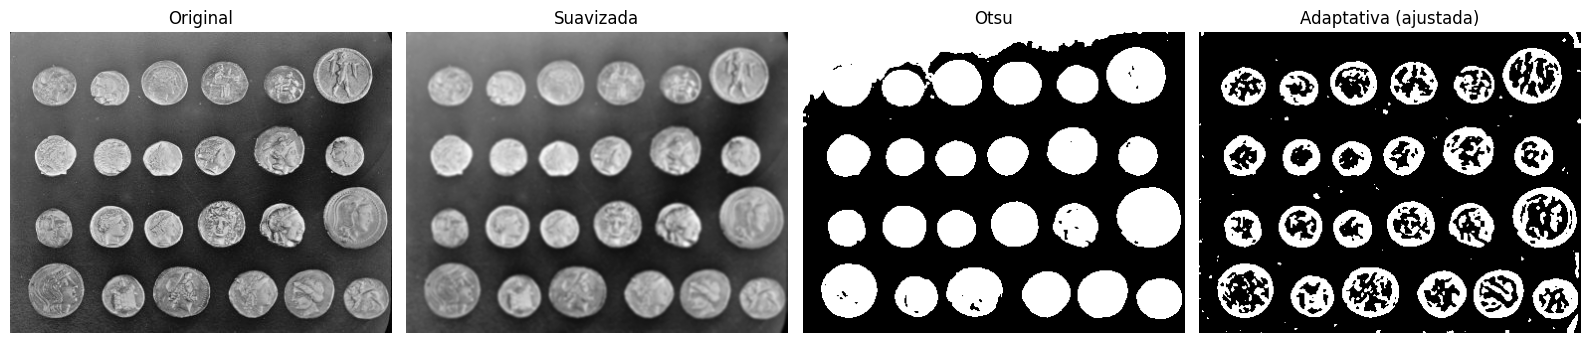

In [12]:
moedas = data.coins()
suave = cv2.GaussianBlur(moedas, (5, 5), 0)

_, mascara_otsu = cv2.threshold(
    suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
mascara_adapt = cv2.adaptiveThreshold(
    suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 31, -5
)
mostrar([moedas, suave, mascara_otsu, mascara_adapt],["Original", "Suavizada", "Otsu", "Adaptativa (ajustada)"],cmap="gray")

In [13]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
MascaraLimpa = cv2.morphologyEx(
    mascara_adapt, cv2.MORPH_CLOSE, kernel
)

contornos, _ = cv2.findContours(MascaraLimpa, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

CotornoMoedas = []
for contorno in contornos:
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)
    circularidade = (4 * np.pi * area / perimetro**2) if perimetro else 0
    if 450 < area < 4000 and circularidade > 0.35:
        CotornoMoedas.append(contorno)


CotornoMoedas.sort(key=lambda c: (cv2.boundingRect(c)[1] // 65, cv2.boundingRect(c)[0]))

print(f"Moedas detectadas pelo algoritmo: {len(CotornoMoedas)}")

Moedas detectadas pelo algoritmo: 24


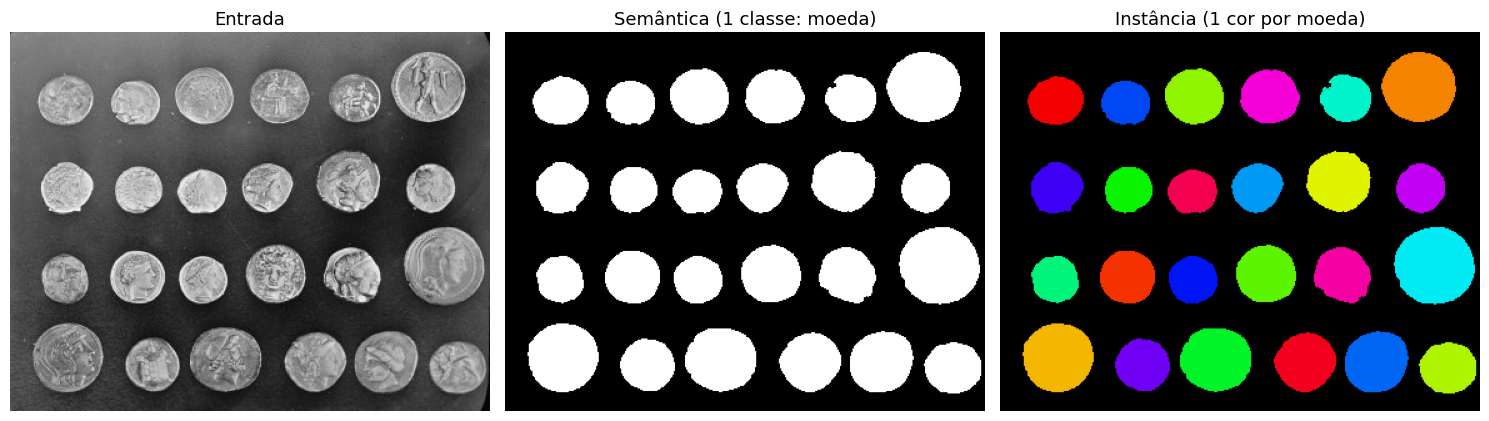

In [14]:
MascaraSemanticaMoedas = np.zeros_like(moedas, dtype=np.uint8)
cv2.drawContours(MascaraSemanticaMoedas, CotornoMoedas, -1, 255, thickness=-1)

rotulos_moedas = np.zeros(moedas.shape, dtype=np.int32)
for identificador, contorno in enumerate(CotornoMoedas, start=1):
    cv2.drawContours(rotulos_moedas, [contorno], -1, identificador, thickness=-1)

def ColoriarInstancias(rotulos):
    resultado = np.zeros((*rotulos.shape, 3), dtype=np.uint8)
    ids = np.unique(rotulos)
    ids = ids[ids > 0]
    for identificador in ids:
        matiz = ((int(identificador) - 1) * 0.61803398875) % 1.0
        cor = (hsv_to_rgb([matiz, 1.0, 0.96]) * 255).astype(np.uint8)
        resultado[rotulos == identificador] = cor
    return resultado

def Comparacao(entrada, semantica, rotulos, nome, arquivo, unidade):
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
    eixos[0].imshow(entrada, cmap="gray" if entrada.ndim == 2 else None)
    eixos[0].set_title("Entrada", fontsize=13)
    eixos[1].imshow(semantica, cmap="gray", vmin=0, vmax=255)
    eixos[1].set_title(f"Semântica (1 classe: {nome})", fontsize=13)
    eixos[2].imshow(ColoriarInstancias(rotulos))
    eixos[2].set_title(f"Instância (1 cor por {unidade})", fontsize=13)
    for eixo in eixos:
        eixo.axis("off")
    fig.tight_layout()
    fig.savefig(arquivo, dpi=180, bbox_inches="tight")
    plt.show()

Comparacao(
    moedas, MascaraSemanticaMoedas, rotulos_moedas,
    nome="moeda", unidade="moeda", arquivo="comparacao_moedas.png"
)

Regiões conectadas de texto detectadas: 141


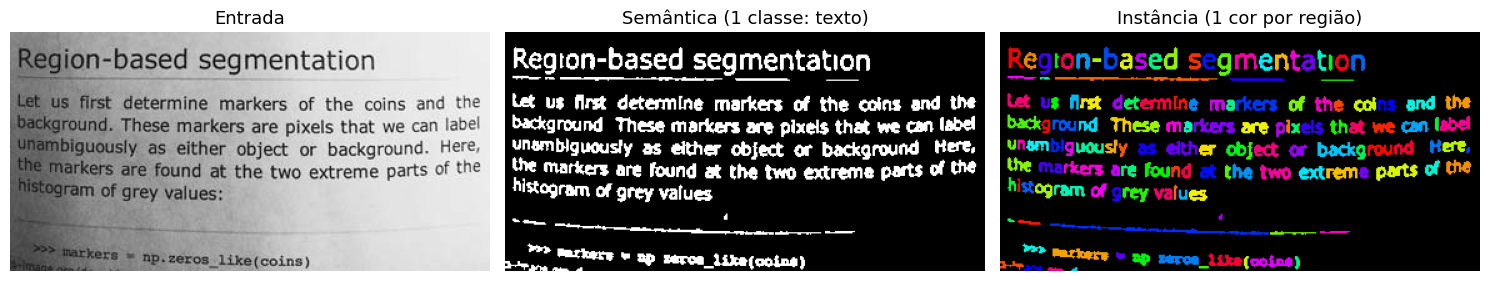

In [15]:
pagina = data.page()
pagina_suave = cv2.GaussianBlur(pagina, (3, 3), 0)
mascara = cv2.adaptiveThreshold(pagina_suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY_INV, 31, 7)
quantidade, rotulos_brutos, estatisticas, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)

rotulos_pagina = np.zeros(pagina.shape, dtype=np.int32)
proximoID = 1
for id_original in range(1, quantidade):  # 0 é o fundo
    area = estatisticas[id_original, cv2.CC_STAT_AREA]
    if area >= 10:
        rotulos_pagina[rotulos_brutos == id_original] = proximoID
        proximoID += 1

mascara_semantica_pagina = np.where(
    rotulos_pagina > 0, 255, 0
).astype(np.uint8)

print(f"Regiões conectadas de texto detectadas: {proximoID - 1}")
Comparacao(pagina, mascara_semantica_pagina, rotulos_pagina,nome="texto", unidade="região", arquivo="comparacao_pagina.png")